# Dataset loading and understanding

In [1]:
import os
import glob
import numpy as np
import pandas as pd

# Find the CSV file attached to the Kaggle notebook
csv_files = glob.glob("/kaggle/input/**/*.csv", recursive=True)

print("CSV files found:")
for file in csv_files:
    print(file)

CSV files found:
/kaggle/input/datasets/mohamedborhenkhlifi/ai4i-2020-predictive-maintenance/ai4i2020.csv


In [2]:
DATA_PATH = "/kaggle/input/datasets/mohamedborhenkhlifi/ai4i-2020-predictive-maintenance/ai4i2020.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

display(df.head())

Dataset loaded successfully.
Number of rows: 10000
Number of columns: 14


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
print("Dataset dimensions:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nFirst five rows:")
display(df.head())

print("\nLast five rows:")
display(df.tail())

Dataset dimensions:
(10000, 14)

Column names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0



Last five rows:


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0
9999,10000,M24859,M,299.0,308.7,1500,40.2,30,0,0,0,0,0,0


In [4]:
print("Missing values per column:")
display(df.isnull().sum().to_frame("Missing values"))

print("Total missing values:", df.isnull().sum().sum())

print("Number of duplicated rows:", df.duplicated().sum())

print("\nData types:")
display(df.dtypes.to_frame("Data type"))

print("\nUnique values per column:")
display(df.nunique().to_frame("Unique values"))

Missing values per column:


,Missing values
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0


Total missing values: 0
Number of duplicated rows: 0

Data types:


,Data type
UDI,int64
Product ID,object
Type,object
Air temperature [K],float64
Process temperature [K],float64
Rotational speed [rpm],int64
Torque [Nm],float64
Tool wear [min],int64
Machine failure,int64
TWF,int64



Unique values per column:


,Unique values
UDI,10000
Product ID,10000
Type,3
Air temperature [K],93
Process temperature [K],82
Rotational speed [rpm],941
Torque [Nm],577
Tool wear [min],246
Machine failure,2
TWF,2


In [5]:
TARGET = "Machine failure"

print("Target values:")
print(sorted(df[TARGET].dropna().unique()))

print("\nTarget counts:")
display(df[TARGET].value_counts().sort_index())

print("\nTarget proportions (%):")
display(
    (df[TARGET].value_counts(normalize=True).sort_index() * 100)
    .round(2)
    .rename("Percentage")
    .to_frame()
)

Target values:
[np.int64(0), np.int64(1)]

Target counts:


Machine failure
0    9661
1     339
Name: count, dtype: int64


Target proportions (%):


,Percentage
Machine failure,
0,96.61
1,3.39


In [7]:
# Target variable
TARGET = "Machine failure"

# Columns excluded from the initial predictor set
LEAKAGE_COLUMNS = [
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF"
]

IDENTIFIER_COLUMNS = [
    "UDI",
    "Product ID"
]

# Create a clean modeling dataset
df_model = df.drop(
    columns=LEAKAGE_COLUMNS + IDENTIFIER_COLUMNS
).copy()

print("Original dataset shape:", df.shape)
print("Modeling dataset shape:", df_model.shape)

print("\nRemaining columns:")
print(df_model.columns.tolist())

Original dataset shape: (10000, 14)
Modeling dataset shape: (10000, 7)

Remaining columns:
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure']


In [8]:
FEATURES = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

X = df_model[FEATURES].copy()
y = df_model[TARGET].copy()

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nFeature data types:")
display(X.dtypes.to_frame("Data type"))

print("\nTarget data type:", y.dtype)

display(X.head())

Feature matrix shape: (10000, 6)
Target vector shape: (10000,)

Feature data types:


,Data type
Type,object
Air temperature [K],float64
Process temperature [K],float64
Rotational speed [rpm],int64
Torque [Nm],float64
Tool wear [min],int64



Target data type: int64


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,M,298.1,308.6,1551,42.8,0
1,L,298.2,308.7,1408,46.3,3
2,L,298.1,308.5,1498,49.4,5
3,L,298.2,308.6,1433,39.5,7
4,L,298.2,308.7,1408,40.0,9


# Exploratory Data Analysis (EDA)

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

sns.set_theme(style="whitegrid")

# Verify the dataset created in Phase 1
assert "df_model" in globals()
assert "Machine failure" in df_model.columns

print("EDA dataset shape:", df_model.shape)
print("Missing values:", df_model.isna().sum().sum())

EDA dataset shape: (10000, 7)
Missing values: 0


In [29]:
TARGET = "Machine failure"

target_counts = df_model[TARGET].value_counts().sort_index()
target_percentages = (
    df_model[TARGET].value_counts(normalize=True).sort_index() * 100
)

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentages.round(2)
})

display(target_summary)

,Count,Percentage
Machine failure,,
0,9661,96.61
1,339,3.39


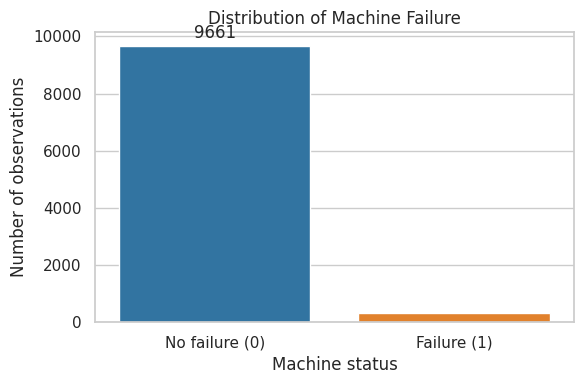

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create data list directly from target_counts
statuses = ["No failure (0)", "Failure (1)"]
counts = [int(target_counts.get(0, 0)), int(target_counts.get(1, 0))]

# Set figure size and plot bar chart
plt.figure(figsize=(6, 4))
ax = sns.barplot(x=statuses, y=counts, hue=statuses, palette=["#1f77b4", "#ff7f0e"], legend=False)

# Add text labels on top of each bar
ax.bar_label(ax.containers[0], padding=3)

# Add titles and axis labels
plt.title("Distribution of Machine Failure")
plt.xlabel("Machine status")
plt.ylabel("Number of observations")

# Adjust layout and render static plot
plt.tight_layout()
plt.show()

In [31]:
NUMERIC_FEATURES = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

display(
    df_model[NUMERIC_FEATURES]
    .describe()
    .T
    .round(2)
)

,count,mean,std,min,25%,50%,75%,max
Air temperature [K],10000.0,300.00,2.00,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,310.01,1.48,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,1538.78,179.28,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,39.99,9.97,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,107.95,63.65,0.0,53.0,108.0,162.0,253.0


In [32]:
for col in NUMERIC_FEATURES:
    fig = px.histogram(
        df_model,
        x=col,
        nbins=40,
        title=f"Distribution of {col}",
        marginal="box",
        opacity=0.85
    )

    fig.update_layout(
        xaxis_title=col,
        yaxis_title="Number of observations",
        showlegend=False
    )

    fig.show()

In [33]:
failure_comparison = (
    df_model.groupby(TARGET)[NUMERIC_FEATURES]
    .agg(["mean", "median", "std"])
    .round(2)
)

display(failure_comparison)

Air temperature [K]              Process temperature [K]  \
                               mean median   std                    mean   
Machine failure                                                            
0                            299.97  300.0  1.99                  310.00   
1                            300.89  301.6  2.07                  310.29   

                             Rotational speed [rpm]                  \
                median   std                   mean  median     std   
Machine failure                                                       
0                310.0  1.49                1540.26  1507.0  167.39   
1                310.4  1.36                1496.49  1365.0  384.94   

                Torque [Nm]               Tool wear [min]                
                       mean median    std            mean median    std  
Machine failure                                                          
0                     39.63   39.9   9.47          106.69  107.0  62.95  
1                     50.17   53.7  16.37          143.78  165.0  72.76

In [34]:
for col in NUMERIC_FEATURES:
    fig = px.box(
        df_model,
        x=TARGET,
        y=col,
        color=TARGET,
        points="outliers",
        title=f"{col} by Machine Failure Status",
        labels={
            TARGET: "Machine failure (0 = No, 1 = Yes)",
            col: col
        }
    )

    fig.show()

In [35]:
type_summary = (
    df_model.groupby("Type", observed=True)[TARGET]
    .agg(
        Total="size",
        Failures="sum",
        Failure_Rate="mean"
    )
)

type_summary["Failure_Rate (%)"] = (
    type_summary["Failure_Rate"] * 100
).round(2)

display(type_summary.drop(columns="Failure_Rate"))

,Total,Failures,Failure_Rate (%)
Type,,,
H,1003,21,2.09
L,6000,235,3.92
M,2997,83,2.77


In [19]:
type_plot = type_summary.reset_index()

fig = px.bar(
    type_plot,
    x="Type",
    y="Failure_Rate",
    text="Failure_Rate (%)",
    title="Machine Failure Rate by Product Type",
    labels={
        "Type": "Product type",
        "Failure_Rate": "Failure rate"
    },
    hover_data=["Total", "Failures", "Failure_Rate (%)"]
)

fig.update_traces(
    texttemplate="%{text:.2f}%",
    textposition="outside"
)

fig.update_layout(
    yaxis_tickformat=".0%",
    yaxis_title="Failure rate",
    xaxis_title="Product type"
)

fig.show()

In [36]:
def calculate_binned_failure_rate(data, feature, target=TARGET, q=5):
    temp = data[[feature, target]].copy()

    temp["Bin"] = pd.qcut(
        temp[feature],
        q=q,
        duplicates="drop"
    )

    result = (
        temp.groupby("Bin", observed=True)[target]
        .agg(Total="size", Failures="sum", Failure_Rate="mean")
        .reset_index()
    )

    result["Failure_Rate (%)"] = result["Failure_Rate"] * 100

    return result

In [37]:
for col in NUMERIC_FEATURES:
    result = calculate_binned_failure_rate(df_model, col)

    print(f"\nFailure rate by {col}:")
    display(
        result[["Bin", "Total", "Failures", "Failure_Rate (%)"]]
        .round(2)
    )


Failure rate by Air temperature [K]:


,Bin,Total,Failures,Failure_Rate (%)
0,"(295.29900000000004, 298.1]",2135,46,2.15
1,"(298.1, 299.2]",1904,48,2.52
2,"(299.2, 300.6]",2091,41,1.96
3,"(300.6, 301.9]",1877,60,3.20
4,"(301.9, 304.5]",1993,144,7.23



Failure rate by Process temperature [K]:


,Bin,Total,Failures,Failure_Rate (%)
0,"(305.699, 308.6]",2168,54,2.49
1,"(308.6, 309.6]",2043,35,1.71
2,"(309.6, 310.5]",1924,92,4.78
3,"(310.5, 311.3]",1944,83,4.27
4,"(311.3, 313.8]",1921,75,3.90



Failure rate by Rotational speed [rpm]:


,Bin,Total,Failures,Failure_Rate (%)
0,"(1167.999, 1405.0]",2007,244,12.16
1,"(1405.0, 1470.0]",2011,29,1.44
2,"(1470.0, 1541.0]",1999,12,0.60
3,"(1541.0, 1644.0]",1992,9,0.45
4,"(1644.0, 2886.0]",1991,45,2.26



Failure rate by Torque [Nm]:


,Bin,Total,Failures,Failure_Rate (%)
0,"(3.799, 31.4]",2002,47,2.35
1,"(31.4, 37.5]",2012,9,0.45
2,"(37.5, 42.7]",2018,12,0.59
3,"(42.7, 48.3]",1985,43,2.17
4,"(48.3, 76.6]",1983,228,11.50



Failure rate by Tool wear [min]:


,Bin,Total,Failures,Failure_Rate (%)
0,"(-0.001, 42.0]",2027,48,2.37
1,"(42.0, 86.0]",2006,42,2.09
2,"(86.0, 130.0]",2014,47,2.33
3,"(130.0, 174.0]",1999,43,2.15
4,"(174.0, 253.0]",1954,159,8.14


In [38]:
for col in NUMERIC_FEATURES:
    result = calculate_binned_failure_rate(df_model, col)

    result["Bin label"] = result["Bin"].astype(str)

    fig = px.bar(
        result,
        x="Bin label",
        y="Failure_Rate (%)",
        text="Failure_Rate (%)",
        title=f"Failure Rate by {col}",
        hover_data=["Total", "Failures"],
        labels={
            "Bin label": f"{col} range",
            "Failure_Rate (%)": "Failure rate (%)"
        }
    )

    fig.update_traces(
        texttemplate="%{text:.2f}%",
        textposition="outside"
    )

    fig.update_layout(
        xaxis_title=f"{col} quantile bins",
        yaxis_title="Failure rate (%)"
    )

    fig.show()

In [40]:
correlation_columns = NUMERIC_FEATURES + [TARGET]

corr_matrix = df_model[correlation_columns].corr(
    method="pearson"
)

display(corr_matrix.round(3))

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
Air temperature [K],1.000,0.876,0.023,-0.014,0.014,0.083
Process temperature [K],0.876,1.000,0.019,-0.014,0.013,0.036
Rotational speed [rpm],0.023,0.019,1.000,-0.875,0.000,-0.044
Torque [Nm],-0.014,-0.014,-0.875,1.000,-0.003,0.191
Tool wear [min],0.014,0.013,0.000,-0.003,1.000,0.105
Machine failure,0.083,0.036,-0.044,0.191,0.105,1.000


In [41]:
fig = px.imshow(
    corr_matrix,
    text_auto=".2f",
    color_continuous_scale="RdBu_r",
    zmin=-1,
    zmax=1,
    aspect="auto",
    title="Correlation Matrix: Operating Conditions and Machine Failure"
)

fig.update_layout(
    width=850,
    height=750
)

fig.show()

In [42]:
outlier_results = []

for col in NUMERIC_FEATURES:
    q1 = df_model[col].quantile(0.25)
    q3 = df_model[col].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    mask = (
        (df_model[col] < lower_bound) |
        (df_model[col] > upper_bound)
    )

    outlier_results.append({
        "Feature": col,
        "Lower bound": lower_bound,
        "Upper bound": upper_bound,
        "Flagged observations": int(mask.sum()),
        "Percentage (%)": round(mask.mean() * 100, 2)
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary)

,Feature,Lower bound,Upper bound,Flagged observations,Percentage (%)
0,Air temperature [K],293.50,306.30,0,0.00
1,Process temperature [K],305.35,314.55,0,0.00
2,Rotational speed [rpm],1139.50,1895.50,418,4.18
3,Torque [Nm],12.80,67.20,69,0.69
4,Tool wear [min],-110.50,325.50,0,0.00


In [43]:
# Descriptive statistics
df_model[NUMERIC_FEATURES].describe().T.to_csv(
    "/kaggle/working/eda_descriptive_statistics.csv"
)

# Class distribution
target_summary.to_csv(
    "/kaggle/working/eda_target_distribution.csv"
)

# Failure rates by type
type_summary.to_csv(
    "/kaggle/working/eda_failure_rate_by_type.csv"
)

# Correlation matrix
corr_matrix.to_csv(
    "/kaggle/working/eda_correlation_matrix.csv"
)

# Outlier summary
outlier_summary.to_csv(
    "/kaggle/working/eda_outlier_summary.csv",
    index=False
)

print("EDA summary tables saved in /kaggle/working/")

EDA summary tables saved in /kaggle/working/


# Data Preparation

In [44]:
# Target and excluded columns
TARGET = "Machine failure"

IDENTIFIER_COLUMNS = [
    "UDI",
    "Product ID"
]

LEAKAGE_COLUMNS = [
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF"
]

# Initial predictor set approved for this experiment
FEATURES = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

# Validate the required columns
required_columns = (
    [TARGET]
    + IDENTIFIER_COLUMNS
    + LEAKAGE_COLUMNS
    + FEATURES
)

missing_columns = set(required_columns) - set(df.columns)

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

# Construct the modeling dataset
df_model = df[FEATURES + [TARGET]].copy()

# Separate predictors and target
X = df_model[FEATURES].copy()
y = df_model[TARGET].astype("int64").copy()

# Validate the target and feature selection
assert y.notna().all(), "Target contains missing values."
assert y.isin([0, 1]).all(), "Target must contain only 0 and 1."
assert not set(LEAKAGE_COLUMNS).intersection(X.columns)
assert not set(IDENTIFIER_COLUMNS).intersection(X.columns)

print("Modeling dataset shape:", df_model.shape)
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nSelected features:")
print(X.columns.tolist())

print("\nTarget distribution:")
display(y.value_counts().sort_index().to_frame("Count"))

Modeling dataset shape: (10000, 7)
Feature matrix shape: (10000, 6)
Target shape: (10000,)

Selected features:
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

Target distribution:


,Count
Machine failure,
0,9661
1,339


In [45]:
from sklearn.model_selection import train_test_split

# Configuration
TEST_SIZE = 0.20
RANDOM_STATE = 42

# Stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training set shape: (8000, 6)
Testing set shape: (2000, 6)

Training target shape: (8000,)
Testing target shape: (2000,)


In [46]:
def summarize_partition(name, target):
    counts = target.value_counts().reindex([0, 1], fill_value=0)

    return {
        "Partition": name,
        "Total observations": len(target),
        "No failure (0)": int(counts[0]),
        "Failure (1)": int(counts[1]),
        "Failure rate (%)": round(
            100 * counts[1] / len(target), 2
        )
    }


split_summary = pd.DataFrame([
    summarize_partition("Training", y_train),
    summarize_partition("Testing", y_test)
])

display(split_summary)

,Partition,Total observations,No failure (0),Failure (1),Failure rate (%)
0,Training,8000,7729,271,3.39
1,Testing,2000,1932,68,3.40


In [47]:
assert set(X_train.index).isdisjoint(set(X_test.index))
assert len(X_train) + len(X_test) == len(X)
assert len(y_train) + len(y_test) == len(y)

print("All split integrity checks passed.")

All split integrity checks passed.


In [48]:
CATEGORICAL_FEATURES = [
    "Type"
]

NUMERIC_FEATURES = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

assert set(CATEGORICAL_FEATURES + NUMERIC_FEATURES) == set(FEATURES)

print("Categorical features:", CATEGORICAL_FEATURES)
print("Numerical features:", NUMERIC_FEATURES)

Categorical features: ['Type']
Numerical features: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']


In [49]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


def make_preprocessor(scale_numeric=True):
    """
    Create a preprocessing pipeline.

    Parameters
    ----------
    scale_numeric : bool
        If True, standardize numerical variables.
        If False, preserve their original scales.
    """

    # Numerical preprocessing
    numerical_steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if scale_numeric:
        numerical_steps.append(
            ("scaler", StandardScaler())
        )

    numerical_pipeline = Pipeline(
        steps=numerical_steps
    )

    # Categorical preprocessing
    categorical_pipeline = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(strategy="most_frequent")
            ),
            (
                "encoder",
                OneHotEncoder(handle_unknown="ignore")
            )
        ]
    )

    # Apply each pipeline to the appropriate columns
    preprocessor = ColumnTransformer(
        transformers=[
            (
                "num",
                numerical_pipeline,
                NUMERIC_FEATURES
            ),
            (
                "cat",
                categorical_pipeline,
                CATEGORICAL_FEATURES
            )
        ],
        remainder="drop"
    )

    return preprocessor

In [50]:
# For Logistic Regression and KNN
preprocessor_scaled = make_preprocessor(
    scale_numeric=True
)

# For Decision Tree, Random Forest and XGBoost
preprocessor_unscaled = make_preprocessor(
    scale_numeric=False
)

In [51]:
# Learn imputation, category encoding and scaling from training data
X_train_scaled = preprocessor_scaled.fit_transform(X_train)
X_test_scaled = preprocessor_scaled.transform(X_test)

print("Scaled training matrix:", X_train_scaled.shape)
print("Scaled testing matrix:", X_test_scaled.shape)

print("\nTransformed feature names:")
print(preprocessor_scaled.get_feature_names_out())

Scaled training matrix: (8000, 8)
Scaled testing matrix: (2000, 8)

Transformed feature names:
['num__Air temperature [K]' 'num__Process temperature [K]'
 'num__Rotational speed [rpm]' 'num__Torque [Nm]' 'num__Tool wear [min]'
 'cat__Type_H' 'cat__Type_L' 'cat__Type_M']


In [52]:
X_train_unscaled = preprocessor_unscaled.fit_transform(X_train)
X_test_unscaled = preprocessor_unscaled.transform(X_test)

print("Unscaled training matrix:", X_train_unscaled.shape)
print("Unscaled testing matrix:", X_test_unscaled.shape)

assert X_train_scaled.shape[0] == len(y_train)
assert X_test_scaled.shape[0] == len(y_test)
assert X_train_unscaled.shape[0] == len(y_train)
assert X_test_unscaled.shape[0] == len(y_test)

print("\nPreprocessing checks passed.")

Unscaled training matrix: (8000, 8)
Unscaled testing matrix: (2000, 8)

Preprocessing checks passed.


In [53]:
from sklearn.linear_model import LogisticRegression

logistic_pipeline = Pipeline([
    (
        "preprocessing",
        make_preprocessor(scale_numeric=True)
    ),
    (
        "model",
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        )
    )
])

In [54]:
from scipy import sparse

# Convert only a small sample to a dense array for inspection
sample = X_train_scaled[:5]

if sparse.issparse(sample):
    sample = sample.toarray()

transformed_feature_names = (
    preprocessor_scaled.get_feature_names_out()
)

X_train_preview = pd.DataFrame(
    sample,
    columns=transformed_feature_names,
    index=X_train.index[:5]
)

display(X_train_preview)

,num__Air temperature [K],num__Process temperature [K],num__Rotational speed [rpm],num__Torque [Nm],num__Tool wear [min],cat__Type_H,cat__Type_L,cat__Type_M
4058,0.998914,0.604282,-0.460607,0.718305,-0.843997,0.0,0.0,1.0
1221,-1.505194,-1.153260,-0.775574,0.638456,0.382263,0.0,0.0,1.0
6895,0.498092,1.077466,-1.007654,0.558607,0.460870,0.0,0.0,1.0
9863,-0.553633,-0.139294,-0.709265,1.626586,-0.372359,0.0,1.0,0.0
8711,-1.455112,-1.018064,1.070019,-1.128202,-0.906882,0.0,1.0,0.0


In [55]:
# Confirm that no leakage columns are in X
assert not any(
    col in X_train.columns
    for col in LEAKAGE_COLUMNS
)

# Confirm that no identifiers are used
assert not any(
    col in X_train.columns
    for col in IDENTIFIER_COLUMNS
)

# Confirm that the classes exist in both partitions
assert set(y_train.unique()) == {0, 1}
assert set(y_test.unique()) == {0, 1}

# Confirm consistent feature sets
assert X_train.columns.tolist() == X_test.columns.tolist()

print("PHASE 3 VALIDATION")
print("------------------")
print("Target:", TARGET)
print("Features:", len(FEATURES))
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Training failures:", int(y_train.sum()))
print("Testing failures:", int(y_test.sum()))
print("Missing values in original modeling features:", int(X.isna().sum().sum()))
print("Excluded leakage columns:", LEAKAGE_COLUMNS)
print("Validation successful.")

PHASE 3 VALIDATION
------------------
Target: Machine failure
Features: 6
Training observations: 8000
Testing observations: 2000
Training failures: 271
Testing failures: 68
Missing values in original modeling features: 0
Excluded leakage columns: ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']
Validation successful.


In [56]:
# Install only if a required package is missing
import importlib.util
import subprocess
import sys

required_packages = {
    "imblearn": "imbalanced-learn",
    "xgboost": "xgboost"
}

missing_packages = [
    package
    for module, package in required_packages.items()
    if importlib.util.find_spec(module) is None
]

if missing_packages:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        *missing_packages
    ])

# General libraries
import os
import numpy as np
import pandas as pd
import joblib

# Scikit-learn
from sklearn.base import clone
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate,
    RandomizedSearchCV
)
from sklearn.metrics import (
    make_scorer,
    precision_score,
    recall_score,
    f1_score
)

# Imbalanced-learn
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler

# Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

print("Libraries imported successfully.")

Libraries imported successfully.


In [58]:
required_variables = [
    "X_train",
    "y_train",
    "X_test",
    "y_test",
    "FEATURES",
    "NUMERIC_FEATURES",
    "CATEGORICAL_FEATURES",
    "TARGET",
    "RANDOM_STATE",
    "make_preprocessor"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Missing Phase 3 variables: "
        + ", ".join(missing_variables)
        + ". Run the relevant Phase 1–3 cells first."
    )

assert X_train.columns.tolist() == FEATURES
assert X_train.index.is_unique
assert set(y_train.unique()) == {0, 1}

print("Training features:", X_train.shape)
print("Training targets:", y_train.shape)
print("Training failures:", int(y_train.sum()))
print("Training normal observations:", int((y_train == 0).sum()))

print("\nTraining target percentages:")
display(
    (y_train.value_counts(normalize=True) * 100)
    .sort_index()
    .rename("Percentage")
    .to_frame()
)

Training features: (8000, 6)
Training targets: (8000,)
Training failures: 271
Training normal observations: 7729

Training target percentages:


,Percentage
Machine failure,
0,96.6125
1,3.3875


In [59]:
CV_SPLITS = 5
N_ITER_SEARCH = 15

cv = StratifiedKFold(
    n_splits=CV_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

SCORING = {
    "pr_auc": "average_precision",
    "roc_auc": "roc_auc",
    "precision": make_scorer(
        precision_score, zero_division=0
    ),
    "recall": make_scorer(
        recall_score, zero_division=0
    ),
    "f1": make_scorer(
        f1_score, zero_division=0
    ),
    "balanced_accuracy": "balanced_accuracy"
}

print("Cross-validation folds:", CV_SPLITS)
print("Primary selection metric: Average Precision")
print("Metrics:", list(SCORING.keys()))


Cross-validation folds: 5
Primary selection metric: Average Precision
Metrics: ['pr_auc', 'roc_auc', 'precision', 'recall', 'f1', 'balanced_accuracy']


In [60]:
BASE_MODELS = {
    "Logistic Regression": {
        "estimator": LogisticRegression(
            max_iter=2000,
            random_state=RANDOM_STATE
        ),
        "scale_numeric": True
    },

    "Decision Tree": {
        "estimator": DecisionTreeClassifier(
            random_state=RANDOM_STATE
        ),
        "scale_numeric": False
    },

    "KNN": {
        "estimator": KNeighborsClassifier(),
        "scale_numeric": True
    },

    "Random Forest": {
        "estimator": RandomForestClassifier(
            n_estimators=200,
            random_state=RANDOM_STATE,
            n_jobs=1
        ),
        "scale_numeric": False
    },

    "XGBoost": {
        "estimator": XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            n_estimators=100,
            max_depth=3,
            learning_rate=0.1,
            tree_method="hist",
            random_state=RANDOM_STATE,
            n_jobs=1
        ),
        "scale_numeric": False
    }
}

print("Models configured:")
for name in BASE_MODELS:
    print("-", name)

Models configured:
- Logistic Regression
- Decision Tree
- KNN
- Random Forest
- XGBoost


In [61]:
def build_pipeline(
    estimator,
    scale_numeric,
    sampler="passthrough"
):
    """
    Build a complete preprocessing and classification pipeline.
    """

    return ImbPipeline(steps=[
        (
            "preprocessing",
            make_preprocessor(
                scale_numeric=scale_numeric
            )
        ),
        (
            "sampler",
            sampler
        ),
        (
            "model",
            clone(estimator)
        )
    ])


# Build one pipeline per classifier
baseline_pipelines = {
    name: build_pipeline(
        estimator=config["estimator"],
        scale_numeric=config["scale_numeric"]
    )
    for name, config in BASE_MODELS.items()
}

print("Baseline pipelines created:", len(baseline_pipelines))

Baseline pipelines created: 5


In [62]:
baseline_rows = []

for name, pipeline in baseline_pipelines.items():
    print(f"Evaluating baseline: {name}")

    cv_results = cross_validate(
        estimator=pipeline,
        X=X_train,
        y=y_train,
        scoring=SCORING,
        cv=cv,
        n_jobs=-1,
        return_train_score=False,
        error_score="raise"
    )

    row = {"Model": name}

    for metric in SCORING:
        scores = cv_results[f"test_{metric}"]

        row[f"{metric} mean"] = scores.mean()
        row[f"{metric} std"] = scores.std(ddof=1)

    baseline_rows.append(row)


baseline_results = pd.DataFrame(baseline_rows)

baseline_results = baseline_results.sort_values(
    by="pr_auc mean",
    ascending=False
).reset_index(drop=True)

display(baseline_results.round(4))

Evaluating baseline: Logistic Regression
Evaluating baseline: Decision Tree
Evaluating baseline: KNN
Evaluating baseline: Random Forest
Evaluating baseline: XGBoost


,Model,pr_auc mean,pr_auc std,roc_auc mean,roc_auc std,precision mean,precision std,recall mean,recall std,f1 mean,f1 std,balanced_accuracy mean,balanced_accuracy std
0,Random Forest,0.7720,0.0245,0.9678,0.0116,0.8749,0.0333,0.4873,0.0551,0.6244,0.0465,0.7424,0.0275
1,XGBoost,0.7546,0.0467,0.9731,0.0121,0.8206,0.0492,0.5650,0.0683,0.6668,0.0528,0.7803,0.0339
2,Decision Tree,0.4882,0.0736,0.8309,0.0312,0.7085,0.0641,0.6716,0.0619,0.6882,0.0527,0.8309,0.0312
3,Logistic Regression,0.4686,0.0356,0.8938,0.0188,0.7607,0.1218,0.1993,0.0309,0.3119,0.0291,0.5984,0.0145
4,KNN,0.4640,0.0298,0.8471,0.0230,0.7949,0.0762,0.3174,0.0315,0.4522,0.0325,0.6572,0.0156


In [63]:
sampler_none = "passthrough"

sampler_moderate = RandomOverSampler(
    sampling_strategy=0.5,
    random_state=RANDOM_STATE
)

sampler_balanced = RandomOverSampler(
    sampling_strategy=1.0,
    random_state=RANDOM_STATE
)

SAMPLER_CHOICES = [
    sampler_none,
    sampler_moderate,
    sampler_balanced
]

print("Available training strategies:")
print("1. No resampling")
print("2. Moderate random oversampling (ratio = 0.5)")
print("3. Full random oversampling (ratio = 1.0)")

Available training strategies:
1. No resampling
2. Moderate random oversampling (ratio = 0.5)
3. Full random oversampling (ratio = 1.0)


In [64]:
PARAM_SPACES = {
    "Logistic Regression": {
        "sampler": SAMPLER_CHOICES,
        "model__C": [0.01, 0.1, 1.0, 10.0, 100.0],
        "model__solver": ["liblinear", "lbfgs"]
    },

    "Decision Tree": {
        "sampler": SAMPLER_CHOICES,
        "model__criterion": ["gini", "entropy"],
        "model__max_depth": [None, 5, 10, 15, 20],
        "model__min_samples_split": [2, 5, 10, 20],
        "model__min_samples_leaf": [1, 2, 5, 10]
    },

    "KNN": {
        "sampler": SAMPLER_CHOICES,
        "model__n_neighbors": [3, 5, 7, 11, 15, 21],
        "model__weights": ["uniform", "distance"],
        "model__p": [1, 2]
    },

    "Random Forest": {
        "sampler": SAMPLER_CHOICES,
        "model__n_estimators": [100, 200, 300],
        "model__max_depth": [None, 8, 16, 24],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": ["sqrt", "log2", 0.8]
    }
}

In [65]:
XGB_COMMON_PARAMS = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [2, 3, 5],
    "model__learning_rate": [0.03, 0.1, 0.2],
    "model__subsample": [0.8, 1.0],
    "model__colsample_bytree": [0.8, 1.0],
    "model__min_child_weight": [1, 3, 5],
    "model__reg_lambda": [1, 5]
}

PARAM_SPACES["XGBoost"] = [
    {
        **XGB_COMMON_PARAMS,
        "sampler": ["passthrough"],
        "model__scale_pos_weight": [1, 5, 10, 20, 28]
    },
    {
        **XGB_COMMON_PARAMS,
        "sampler": [
            sampler_moderate,
            sampler_balanced
        ],
        "model__scale_pos_weight": [1]
    }
]

print("Hyperparameter search spaces defined:")
for name, space in PARAM_SPACES.items():
    print(f"- {name}")

Hyperparameter search spaces defined:
- Logistic Regression
- Decision Tree
- KNN
- Random Forest
- XGBoost


In [66]:
searches = {}
tuned_pipelines = {}
tuned_rows = []

for name, config in BASE_MODELS.items():
    print("\n" + "=" * 70)
    print(f"Tuning: {name}")
    print("=" * 70)

    pipeline = build_pipeline(
        estimator=config["estimator"],
        scale_numeric=config["scale_numeric"]
    )

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=PARAM_SPACES[name],
        n_iter=N_ITER_SEARCH,
        scoring=SCORING,
        refit="pr_auc",
        cv=cv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=1,
        return_train_score=False,
        error_score="raise",
        pre_dispatch="2*n_jobs"
    )

    # IMPORTANT: only the training split is used here
    search.fit(X_train, y_train)

    searches[name] = search
    tuned_pipelines[name] = search.best_estimator_

    best_index = search.best_index_
    cv_results = search.cv_results_

    row = {
        "Model": name,
        "Best CV PR-AUC": search.best_score_,
        "Best parameters": str(search.best_params_)
    }

    for metric in SCORING:
        row[f"{metric} mean"] = cv_results[
            f"mean_test_{metric}"
        ][best_index]

        row[f"{metric} std"] = cv_results[
            f"std_test_{metric}"
        ][best_index]

    tuned_rows.append(row)

print("\nAll five hyperparameter searches completed.")


Tuning: Logistic Regression
Fitting 5 folds for each of 15 candidates, totalling 75 fits

Tuning: Decision Tree
Fitting 5 folds for each of 15 candidates, totalling 75 fits

Tuning: KNN
Fitting 5 folds for each of 15 candidates, totalling 75 fits

Tuning: Random Forest
Fitting 5 folds for each of 15 candidates, totalling 75 fits

Tuning: XGBoost
Fitting 5 folds for each of 15 candidates, totalling 75 fits

All five hyperparameter searches completed.


In [67]:
tuned_results = pd.DataFrame(tuned_rows)

tuned_results = tuned_results.sort_values(
    by="Best CV PR-AUC",
    ascending=False
).reset_index(drop=True)

metrics_to_display = [
    "Model",
    "pr_auc mean",
    "pr_auc std",
    "roc_auc mean",
    "precision mean",
    "recall mean",
    "f1 mean",
    "balanced_accuracy mean"
]

print("Tuned models — cross-validation results")
display(
    tuned_results[metrics_to_display]
    .round(4)
)

Tuned models — cross-validation results


,Model,pr_auc mean,pr_auc std,roc_auc mean,precision mean,recall mean,f1 mean,balanced_accuracy mean
0,Random Forest,0.8179,0.0193,0.9723,0.8724,0.6494,0.7423,0.8230
1,XGBoost,0.7791,0.0338,0.9711,0.7580,0.7198,0.7372,0.8558
2,Decision Tree,0.6750,0.0365,0.8744,0.7853,0.6716,0.7229,0.8325
3,KNN,0.5712,0.0339,0.8820,0.8500,0.2326,0.3638,0.6156
4,Logistic Regression,0.4703,0.0327,0.8932,0.9169,0.1366,0.2369,0.5681


In [68]:
for name in tuned_results["Model"]:
    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print("Best CV Average Precision:")
    print(round(searches[name].best_score_, 4))

    print("\nSelected hyperparameters:")
    print(searches[name].best_params_)


Random Forest
Best CV Average Precision:
0.8179

Selected hyperparameters:
{'sampler': 'passthrough', 'model__n_estimators': 200, 'model__min_samples_split': 5, 'model__min_samples_leaf': 4, 'model__max_features': 0.8, 'model__max_depth': 16}

XGBoost
Best CV Average Precision:
0.7791

Selected hyperparameters:
{'sampler': 'passthrough', 'model__subsample': 0.8, 'model__scale_pos_weight': 5, 'model__reg_lambda': 5, 'model__n_estimators': 200, 'model__min_child_weight': 1, 'model__max_depth': 5, 'model__learning_rate': 0.2, 'model__colsample_bytree': 1.0}

Decision Tree
Best CV Average Precision:
0.675

Selected hyperparameters:
{'sampler': 'passthrough', 'model__min_samples_split': 10, 'model__min_samples_leaf': 5, 'model__max_depth': None, 'model__criterion': 'gini'}

KNN
Best CV Average Precision:
0.5712

Selected hyperparameters:
{'sampler': 'passthrough', 'model__weights': 'distance', 'model__p': 2, 'model__n_neighbors': 11}

Logistic Regression
Best CV Average Precision:
0.4703



In [69]:
baseline_comparison = baseline_results[
    [
        "Model",
        "pr_auc mean",
        "roc_auc mean",
        "precision mean",
        "recall mean",
        "f1 mean"
    ]
].copy()

tuned_comparison = tuned_results[
    [
        "Model",
        "pr_auc mean",
        "roc_auc mean",
        "precision mean",
        "recall mean",
        "f1 mean"
    ]
].copy()

comparison = baseline_comparison.merge(
    tuned_comparison,
    on="Model",
    suffixes=("_baseline", "_tuned")
)

comparison = comparison.sort_values(
    by="pr_auc mean_tuned",
    ascending=False
).reset_index(drop=True)

display(comparison.round(4))

,Model,pr_auc mean_baseline,roc_auc mean_baseline,precision mean_baseline,recall mean_baseline,f1 mean_baseline,pr_auc mean_tuned,roc_auc mean_tuned,precision mean_tuned,recall mean_tuned,f1 mean_tuned
0,Random Forest,0.7720,0.9678,0.8749,0.4873,0.6244,0.8179,0.9723,0.8724,0.6494,0.7423
1,XGBoost,0.7546,0.9731,0.8206,0.5650,0.6668,0.7791,0.9711,0.7580,0.7198,0.7372
2,Decision Tree,0.4882,0.8309,0.7085,0.6716,0.6882,0.6750,0.8744,0.7853,0.6716,0.7229
3,KNN,0.4640,0.8471,0.7949,0.3174,0.4522,0.5712,0.8820,0.8500,0.2326,0.3638
4,Logistic Regression,0.4686,0.8938,0.7607,0.1993,0.3119,0.4703,0.8932,0.9169,0.1366,0.2369


In [70]:
OUTPUT_DIR = "/kaggle/working/phase4_outputs"
MODEL_DIR = os.path.join(OUTPUT_DIR, "models")

os.makedirs(MODEL_DIR, exist_ok=True)

# Save baseline and tuned comparison tables
baseline_results.to_csv(
    os.path.join(OUTPUT_DIR, "baseline_cv_results.csv"),
    index=False
)

tuned_results.to_csv(
    os.path.join(OUTPUT_DIR, "tuned_cv_results.csv"),
    index=False
)

comparison.to_csv(
    os.path.join(OUTPUT_DIR, "baseline_vs_tuned_cv.csv"),
    index=False
)

# Save each best fitted pipeline and its full search results
for name, search in searches.items():
    slug = (
        name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    model_path = os.path.join(
        MODEL_DIR,
        f"{slug}_best_pipeline.joblib"
    )

    joblib.dump(
        search.best_estimator_,
        model_path
    )

    pd.DataFrame(
        search.cv_results_
    ).to_csv(
        os.path.join(
            OUTPUT_DIR,
            f"{slug}_search_results.csv"
        ),
        index=False
    )

# Save all selected pipelines in one bundle as well
joblib.dump(
    tuned_pipelines,
    os.path.join(MODEL_DIR, "all_best_pipelines.joblib")
)

print("Saved results and models to:", OUTPUT_DIR)

print("\nGenerated files:")
for root, dirs, files in os.walk(OUTPUT_DIR):
    for filename in files:
        print(os.path.join(root, filename))

Saved results and models to: /kaggle/working/phase4_outputs

Generated files:
/kaggle/working/phase4_outputs/baseline_vs_tuned_cv.csv
/kaggle/working/phase4_outputs/logistic_regression_search_results.csv
/kaggle/working/phase4_outputs/random_forest_search_results.csv
/kaggle/working/phase4_outputs/baseline_cv_results.csv
/kaggle/working/phase4_outputs/tuned_cv_results.csv
/kaggle/working/phase4_outputs/decision_tree_search_results.csv
/kaggle/working/phase4_outputs/xgboost_search_results.csv
/kaggle/working/phase4_outputs/knn_search_results.csv
/kaggle/working/phase4_outputs/models/all_best_pipelines.joblib
/kaggle/working/phase4_outputs/models/logistic_regression_best_pipeline.joblib
/kaggle/working/phase4_outputs/models/decision_tree_best_pipeline.joblib
/kaggle/working/phase4_outputs/models/knn_best_pipeline.joblib
/kaggle/working/phase4_outputs/models/xgboost_best_pipeline.joblib
/kaggle/working/phase4_outputs/models/random_forest_best_pipeline.joblib


In [71]:
best_model_name = tuned_results.iloc[0]["Model"]
best_search = searches[best_model_name]

print("CURRENT LEADING MODEL")
print("---------------------")
print("Model:", best_model_name)
print(
    "Cross-validated Average Precision:",
    round(best_search.best_score_, 4)
)

print("\nSelected parameters:")
print(best_search.best_params_)

print("\nTraining observations used for final refit:", len(X_train))
print("Held-out test observations used in Phase 4: 0")

CURRENT LEADING MODEL
---------------------
Model: Random Forest
Cross-validated Average Precision: 0.8179

Selected parameters:
{'sampler': 'passthrough', 'model__n_estimators': 200, 'model__min_samples_split': 5, 'model__min_samples_leaf': 4, 'model__max_features': 0.8, 'model__max_depth': 16}

Training observations used for final refit: 8000
Held-out test observations used in Phase 4: 0


# Model evaluation and comparison

In [72]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
    auc
)

# Verify that Phase 4 results exist
required_objects = [
    "X_test",
    "y_test",
    "searches",
    "tuned_results",
    "RANDOM_STATE"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        "Missing Phase 4 objects: "
        + ", ".join(missing_objects)
        + ". Run the Phase 4 training and tuning cells first."
    )

if len(searches) != 5:
    raise ValueError(
        f"Expected 5 tuned models, found {len(searches)}."
    )

# Ensure the selected model is based on cross-validation,
# not on the test results.
best_model_name = (
    tuned_results
    .sort_values("Best CV PR-AUC", ascending=False)
    .iloc[0]["Model"]
)

best_model = searches[best_model_name].best_estimator_

print("Number of tuned models:", len(searches))
print("Test set size:", len(X_test))
print("Selected model from Phase 4:", best_model_name)

print(
    "Best cross-validated Average Precision:",
    round(searches[best_model_name].best_score_, 4)
)

Number of tuned models: 5
Test set size: 2000
Selected model from Phase 4: Random Forest
Best cross-validated Average Precision: 0.8179


In [76]:
DEFAULT_THRESHOLD = 0.50

test_probabilities = {}
test_predictions = {}
test_results = []

y_test_eval = np.asarray(y_test).astype(int)

for name, search in searches.items():

    # Best pipeline was refitted on X_train, y_train by RandomizedSearchCV
    pipeline = search.best_estimator_

    # Probability that the observation belongs to failure class 1
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    # Apply a consistent decision threshold
    predictions = (
        probabilities >= DEFAULT_THRESHOLD
    ).astype(int)

    test_probabilities[name] = probabilities
    test_predictions[name] = predictions

    # Basic classification metrics
    accuracy = accuracy_score(y_test_eval, predictions)

    precision = precision_score(
        y_test_eval, predictions, zero_division=0
    )

    recall = recall_score(
        y_test_eval, predictions, zero_division=0
    )

    f1 = f1_score(
        y_test_eval, predictions, zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        y_test_eval, predictions
    )

    # Probability-based metrics
    roc_auc = roc_auc_score(
        y_test_eval, probabilities
    )

    average_precision = average_precision_score(
        y_test_eval, probabilities
    )

    pr_precision, pr_recall, _ = precision_recall_curve(
        y_test_eval, probabilities
    )

    pr_auc = auc(pr_recall, pr_precision)

    # Confusion matrix counts
    tn, fp, fn, tp = confusion_matrix(
        y_test_eval, predictions, labels=[0, 1]
    ).ravel()

    specificity = tn / (tn + fp) if (tn + fp) else 0.0

    test_results.append({
        "Model": name,
        "Threshold": DEFAULT_THRESHOLD,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "Specificity": specificity,
        "Balanced accuracy": balanced_acc,
        "ROC-AUC": roc_auc,
        "PR-AUC (trapezoidal)": pr_auc,
        "Average Precision": average_precision,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

test_results_df = pd.DataFrame(test_results)

print("Test-set results for all tuned classifiers")
display(
    test_results_df
    .sort_values("Average Precision", ascending=False)
    .round(4)
)

Test-set results for all tuned classifiers


,Model,Threshold,Accuracy,Precision,Recall,F1-score,Specificity,Balanced accuracy,ROC-AUC,PR-AUC (trapezoidal),Average Precision,TN,FP,FN,TP
3,Random Forest,0.5,0.9855,0.8421,0.7059,0.7680,0.9953,0.8506,0.9702,0.8391,0.8385,1923,9,20,48
4,XGBoost,0.5,0.9860,0.8226,0.7500,0.7846,0.9943,0.8722,0.9734,0.8272,0.8279,1921,11,17,51
1,Decision Tree,0.5,0.9845,0.7761,0.7647,0.7704,0.9922,0.8785,0.8847,0.7709,0.6944,1917,15,16,52
2,KNN,0.5,0.9715,0.9231,0.1765,0.2963,0.9995,0.5880,0.8953,0.5715,0.5585,1931,1,56,12
0,Logistic Regression,0.5,0.9685,0.8571,0.0882,0.1600,0.9995,0.5439,0.8983,0.4094,0.4134,1931,1,62,6


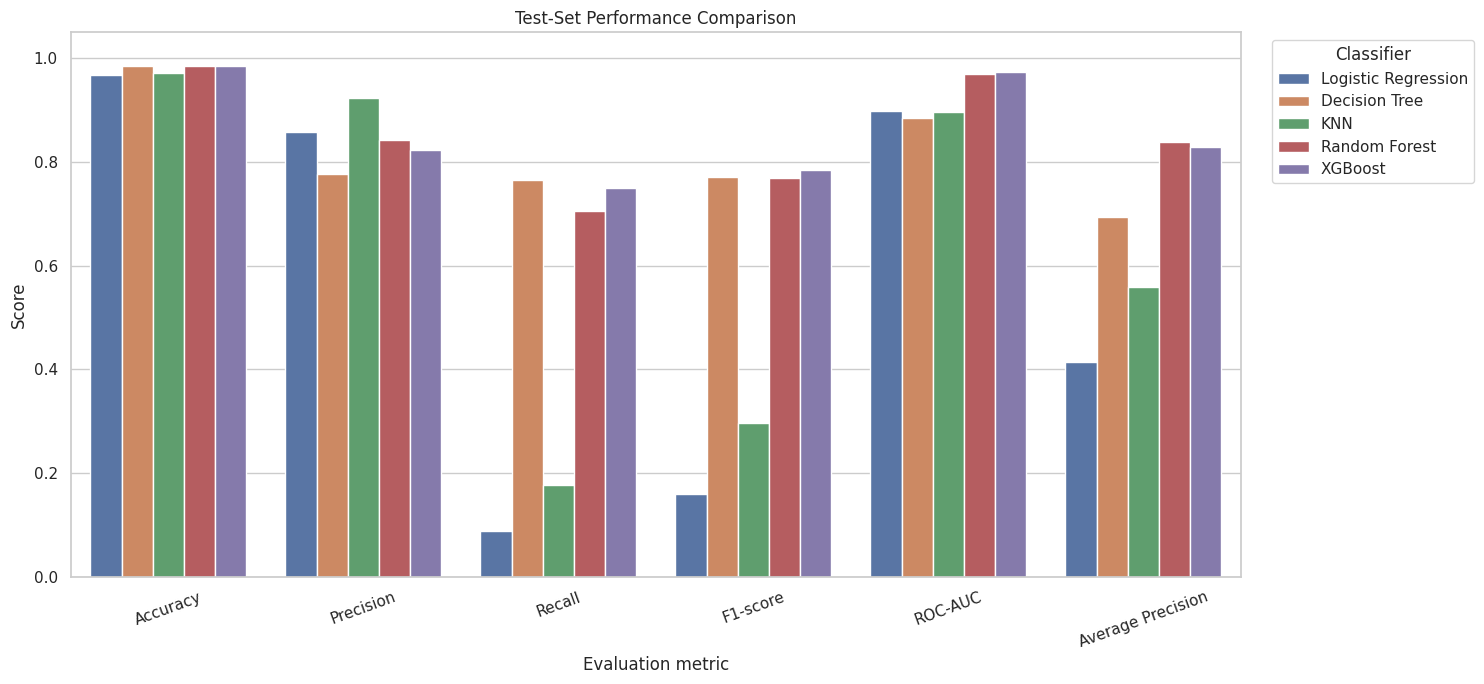

In [77]:
comparison_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC",
    "Average Precision"
]

plot_data = test_results_df[
    ["Model"] + comparison_metrics
].melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

fig, ax = plt.subplots(figsize=(15, 7))

sns.barplot(
    data=plot_data,
    x="Metric",
    y="Score",
    hue="Model",
    ax=ax
)

ax.set_title("Test-Set Performance Comparison")
ax.set_xlabel("Evaluation metric")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.legend(title="Classifier", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

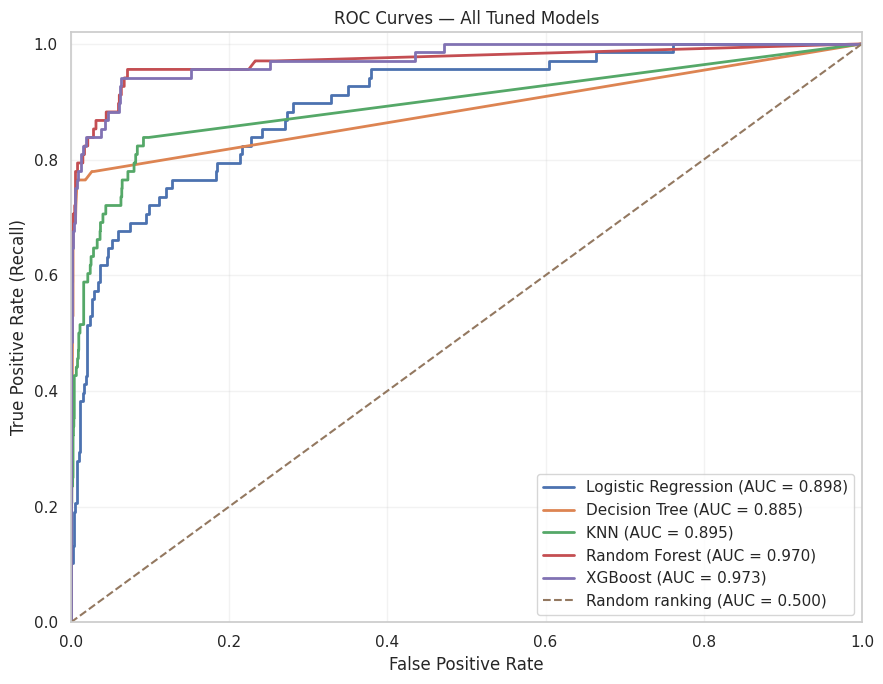

In [78]:
fig, ax = plt.subplots(figsize=(9, 7))

for name, probabilities in test_probabilities.items():
    fpr, tpr, _ = roc_curve(
        y_test_eval, probabilities
    )

    roc_score = roc_auc_score(
        y_test_eval, probabilities
    )

    ax.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {roc_score:.3f})"
    )

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random ranking (AUC = 0.500)"
)

ax.set_title("ROC Curves — All Tuned Models")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate (Recall)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(loc="lower right")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

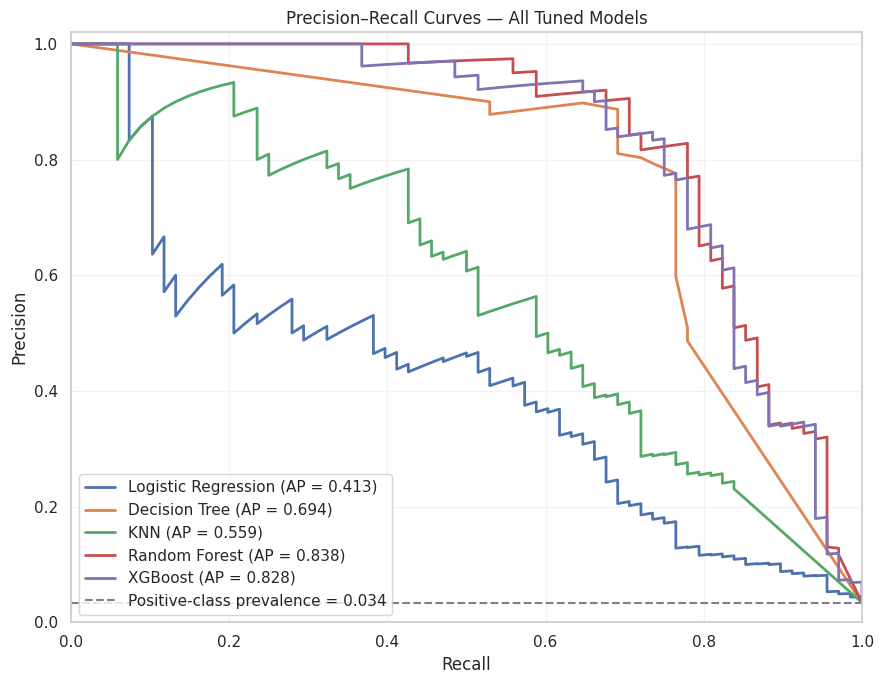

In [79]:
fig, ax = plt.subplots(figsize=(9, 7))

failure_prevalence = y_test_eval.mean()

for name, probabilities in test_probabilities.items():
    precision_curve, recall_curve, _ = precision_recall_curve(
        y_test_eval, probabilities
    )

    ap = average_precision_score(
        y_test_eval, probabilities
    )

    ax.plot(
        recall_curve,
        precision_curve,
        linewidth=2,
        label=f"{name} (AP = {ap:.3f})"
    )

ax.axhline(
    y=failure_prevalence,
    color="gray",
    linestyle="--",
    label=f"Positive-class prevalence = {failure_prevalence:.3f}"
)

ax.set_title("Precision–Recall Curves — All Tuned Models")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(loc="best")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [82]:
best_predictions = test_predictions[best_model_name]
best_probabilities = test_probabilities[best_model_name]

print("=" * 65)
print("FINAL CANDIDATE MODEL — TEST-SET EVALUATION")
print("=" * 65)

print("Model:", best_model_name)
print("Decision threshold:", DEFAULT_THRESHOLD)

tn, fp, fn, tp = confusion_matrix(
    y_test_eval,
    best_predictions,
    labels=[0, 1]
).ravel()

# Calculate PR curve components safely
precision_vals, recall_vals, _ = precision_recall_curve(y_test_eval, best_probabilities)

best_metrics = {
    "Accuracy": accuracy_score(y_test_eval, best_predictions),
    "Precision": precision_score(
        y_test_eval, best_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test_eval, best_predictions, zero_division=0
    ),
    "F1-score": f1_score(
        y_test_eval, best_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_test_eval, best_probabilities
    ),
    "PR-AUC (trapezoidal)": auc(recall_vals[::-1], precision_vals[::-1]),
    "Average Precision": average_precision_score(
        y_test_eval, best_probabilities
    ),
    "Specificity": tn / (tn + fp) if tn + fp else 0.0,
    "Balanced accuracy": balanced_accuracy_score(
        y_test_eval, best_predictions
    )
}

best_metrics_df = pd.DataFrame(
    {
        "Metric": list(best_metrics.keys()),
        "Value": list(best_metrics.values())
    }
)

display(best_metrics_df.round(4))

print("\nClassification report:")
print(
    classification_report(
        y_test_eval,
        best_predictions,
        labels=[0, 1],
        target_names=["No failure (0)", "Failure (1)"],
        digits=4,
        zero_division=0
    )
)

FINAL CANDIDATE MODEL — TEST-SET EVALUATION
Model: Random Forest
Decision threshold: 0.5


,Metric,Value
0,Accuracy,0.9855
1,Precision,0.8421
2,Recall,0.7059
3,F1-score,0.7680
4,ROC-AUC,0.9702
5,PR-AUC (trapezoidal),0.8391
6,Average Precision,0.8385
7,Specificity,0.9953
8,Balanced accuracy,0.8506



Classification report:
                precision    recall  f1-score   support

No failure (0)     0.9897    0.9953    0.9925      1932
   Failure (1)     0.8421    0.7059    0.7680        68

      accuracy                         0.9855      2000
     macro avg     0.9159    0.8506    0.8803      2000
  weighted avg     0.9847    0.9855    0.9849      2000



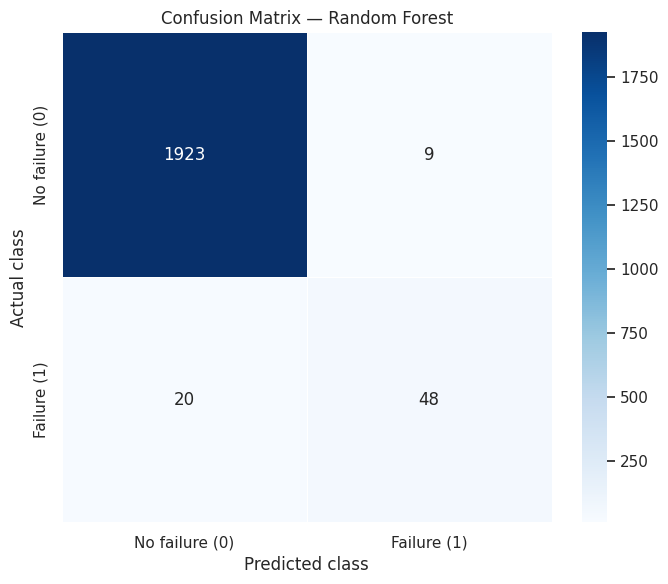

True negatives  (TN): 1923
False positives (FP): 9
False negatives (FN): 20
True positives  (TP): 48


In [83]:
cm = confusion_matrix(
    y_test_eval,
    best_predictions,
    labels=[0, 1]
)

fig, ax = plt.subplots(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5,
    xticklabels=["No failure (0)", "Failure (1)"],
    yticklabels=["No failure (0)", "Failure (1)"],
    ax=ax
)

ax.set_title(f"Confusion Matrix — {best_model_name}")
ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")

plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()

print(f"True negatives  (TN): {tn}")
print(f"False positives (FP): {fp}")
print(f"False negatives (FN): {fn}")
print(f"True positives  (TP): {tp}")

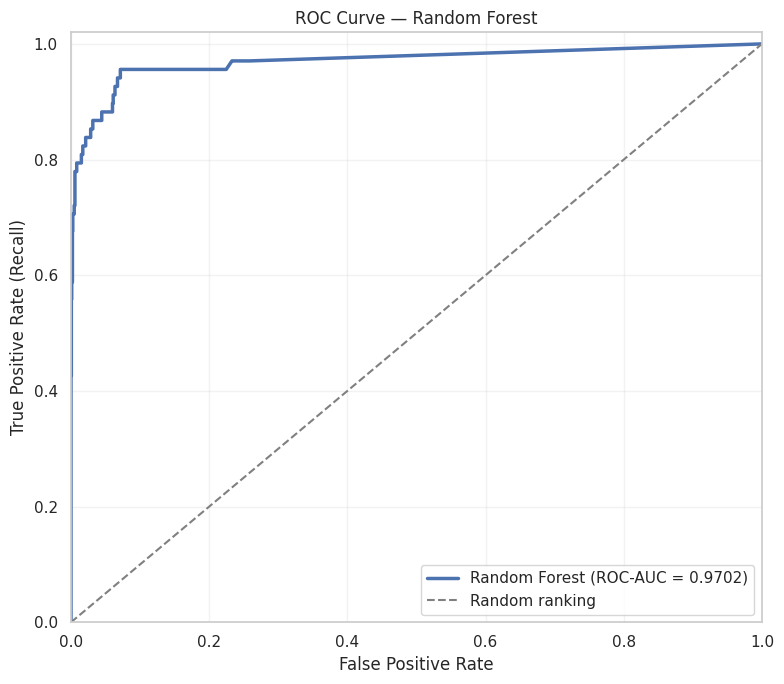

In [84]:
fpr, tpr, roc_thresholds = roc_curve(
    y_test_eval,
    best_probabilities
)

best_roc_auc = roc_auc_score(
    y_test_eval,
    best_probabilities
)

fig, ax = plt.subplots(figsize=(8, 7))

ax.plot(
    fpr,
    tpr,
    linewidth=2.5,
    label=f"{best_model_name} (ROC-AUC = {best_roc_auc:.4f})"
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random ranking"
)

ax.set_title(f"ROC Curve — {best_model_name}")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate (Recall)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(loc="lower right")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [87]:
from IPython.display import display
import ipywidgets as widgets


def evaluate_at_threshold(threshold):
    predictions = (
        best_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test_eval,
        predictions,
        labels=[0, 1]
    ).ravel()

    metrics = pd.DataFrame({
        "Metric": [
            "Threshold",
            "Accuracy",
            "Precision",
            "Recall",
            "F1-score",
            "Specificity"
        ],
        "Value": [
            threshold,
            accuracy_score(y_test_eval, predictions),
            precision_score(
                y_test_eval, predictions, zero_division=0
            ),
            recall_score(
                y_test_eval, predictions, zero_division=0
            ),
            f1_score(
                y_test_eval, predictions, zero_division=0
            ),
            tn / (tn + fp) if (tn + fp) else 0.0
        ]
    })

    display(metrics.round(4))

    cm = confusion_matrix(
        y_test_eval,
        predictions,
        labels=[0, 1]
    )

    fig, ax = plt.subplots(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No failure", "Failure"],
        yticklabels=["No failure", "Failure"],
        ax=ax
    )

    ax.set_title(
        f"{best_model_name} — Threshold = {threshold:.2f}"
    )
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")

    plt.tight_layout()
    plt.show()

In [88]:
threshold_slider = widgets.FloatSlider(
    value=0.50,
    min=0.01,
    max=0.99,
    step=0.01,
    description="Threshold:",
    readout_format=".2f",
    continuous_update=False,
    style={"description_width": "initial"},
    layout=widgets.Layout(width="600px")
)

widgets.interactive(
    evaluate_at_threshold,
    threshold=threshold_slider
)

interactive(children=(FloatSlider(value=0.5, continuous_update=False, description='Threshold:', layout=Layout(…

,Metric,Value
0,Threshold,0.3000
1,Accuracy,0.9850
2,Precision,0.7794
3,Recall,0.7794
4,F1-score,0.7794
5,Specificity,0.9922


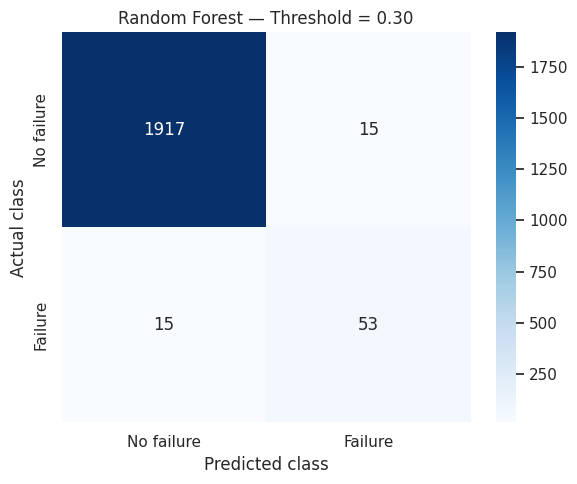

,Metric,Value
0,Threshold,0.5000
1,Accuracy,0.9855
2,Precision,0.8421
3,Recall,0.7059
4,F1-score,0.7680
5,Specificity,0.9953


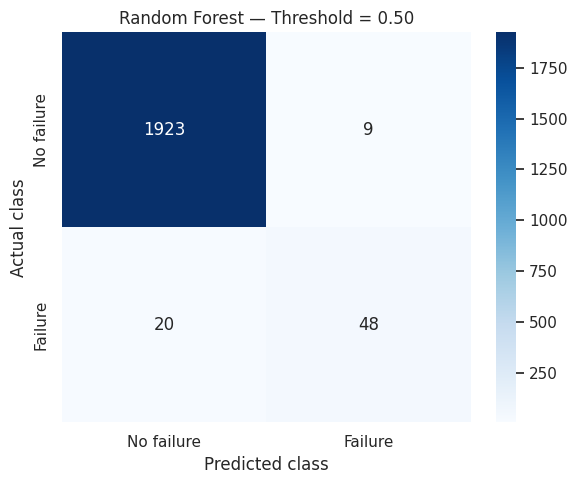

,Metric,Value
0,Threshold,0.7000
1,Accuracy,0.9825
2,Precision,0.9714
3,Recall,0.5000
4,F1-score,0.6602
5,Specificity,0.9995


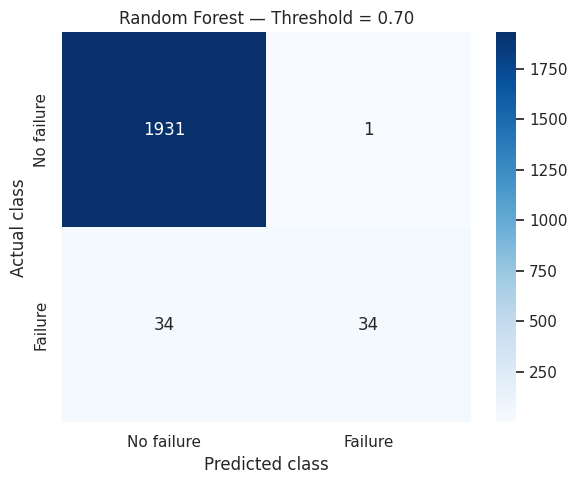

In [89]:
evaluate_at_threshold(0.30)
evaluate_at_threshold(0.50)
evaluate_at_threshold(0.70)

In [90]:
EVALUATION_DIR = "/kaggle/working/phase5_outputs"
os.makedirs(EVALUATION_DIR, exist_ok=True)

test_results_df.to_csv(
    os.path.join(EVALUATION_DIR, "all_models_test_metrics.csv"),
    index=False
)

best_metrics_df.to_csv(
    os.path.join(EVALUATION_DIR, "best_model_metrics.csv"),
    index=False
)

best_confusion_matrix = pd.DataFrame(
    cm,
    index=["Actual no failure", "Actual failure"],
    columns=["Predicted no failure", "Predicted failure"]
)

best_confusion_matrix.to_csv(
    os.path.join(EVALUATION_DIR, "best_model_confusion_matrix.csv")
)

print("Evaluation results saved to:", EVALUATION_DIR)

Evaluation results saved to: /kaggle/working/phase5_outputs
